In [ ]:
from torchvision import datasets, transforms
import torch
import torch.nn as nn 
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
from pathlib import Path
from dataclasses import dataclass, fields
from typing import Tuple, List
import pandas as pd
import json

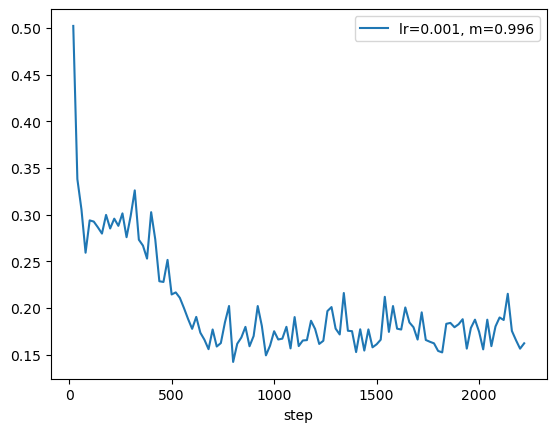

In [12]:
runs = {}
for run_dir in sorted(Path("runs").iterdir()):
    cfg = json.loads((run_dir / "config.json").read_text())
    df  = pd.read_json(run_dir / "metrics.jsonl", lines=True)
    runs[run_dir.name] = (cfg, df)

ax = plt.gca()
for name, (cfg, df) in runs.items():
    label = f"lr={cfg['model']['context_learning_rate']}, m={cfg['model']['momentum']}"
    df.plot(x="step", y="loss", ax=ax, label=label)